# ColorMNIST Ablation: Riesz MMD Flow Directly on Pixels (No Encoder, No Decoder)

The sibling samplers all involve the autoencoder: the reference pipeline flows
*latents* and decodes, and the pullback ablation flows pixels but differentiates
*through the encoder*. Here the autoencoder is removed from the sampler entirely —
particles are raw flattened images and the kernel is the Riesz/energy kernel
$k(y, y') = -\lVert y - y' \rVert$ on pixels — so there is no encoder to fool and no
decoder to project onto the image manifold.

The estimation half is unchanged from
`ColorMNIST_DR_IMQ_MMD_Flow_Euler_Arm1_RefParams_SplitAE` (same data, same disjoint
autoencoder split, same cross-fitted DR weights $v$; the autoencoder survives only
inside the ridge cross-validation that selects the DR regularisation), so the
comparison isolates the sampler. The flow uses AdamW with warm-up and cosine decay:
plain forward Euler diverges here at every step, which is expected for a scale-free
kernel with a fixed step in unconstrained high dimension.

In [1]:
import sys

import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

sys.path.append("../../src")
torch.set_default_dtype(torch.float32)

from data_utils import (color_ratio, load_digit_pools, sample_interventional,
                        sample_observed, to_image_range, to_model_range)
from autoencoder_utils import encode_in_batches, train_conv_ae
from kernel_utils import RBF, RieszKernel
from causality_utils import (cpme_dr_weights_crossfit, make_crossfit_fold_ids,
                             select_regularization)
from dens_ratio_utils import crossfit_propensity
from mmd_flow_utils import adamw_riesz_flow, squared_mmd
from metric_utils import sliced_wasserstein

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


## 1. Data and Cross-Fitted DR Weights

Unchanged from the reference notebook, and reported only as the two numbers that
matter downstream: the on-arm effective sample size and $\sum_i v_i$.

In [2]:
N_OBS, TARGET_A = 20000, 1
W_CONF, TAU, ALPHA, K_MASK = 10.0, 0.08, 0.0, 10.0
N_AE, N_DR, M = 10000, 4000, 1600

pools = load_digit_pools(root="../../data", device=device)
generator = torch.Generator(device=device).manual_seed(SEED)
X_obs, A_obs, Y_obs = sample_observed(pools, N_OBS, w_conf=W_CONF, tau=TAU,
                                      alpha=ALPHA, k_mask=K_MASK, generator=generator)
data = to_model_range(Y_obs)

split = torch.randperm(N_OBS, generator=torch.Generator(device=device).manual_seed(SEED + 2),
                       device=device)
ae_idx, causal_idx = split[:N_AE], split[N_AE:]
arm_causal = causal_idx[A_obs[causal_idx] == TARGET_A]

ae, _ = train_conv_ae(data[ae_idx], latent_dim=32, n_iterations=3000, batch_size=128,
                      learning_rate=1e-3, device=device,
                      generator=torch.Generator(device=device).manual_seed(SEED),
                      log_every=1500, verbose=False)
for parameter in ae.parameters():
    parameter.requires_grad_(False)

pick_dr = torch.randperm(len(causal_idx),
                         generator=torch.Generator(device=device).manual_seed(SEED + 5),
                         device=device)[:N_DR]
subsample = causal_idx[pick_dr]
X_s, A_s = X_obs[subsample], A_obs[subsample]
Z_s = encode_in_batches(ae.encode, data[subsample])

fold_ids = make_crossfit_fold_ids(N_DR, n_folds=5, seed=0)
torch.manual_seed(SEED)
e1 = crossfit_propensity(X_s.unsqueeze(1).double().cpu(), A_s.double().cpu(), fold_ids)
w_hat = (A_s.cpu() == TARGET_A).double() / (e1 if TARGET_A == 1 else 1.0 - e1)
on_arm = w_hat[A_s.cpu() == TARGET_A]

kernel_x = RBF(use_length_scale_heuristic=True)
K_x = kernel_x(X_s.unsqueeze(1).double().cpu())
K_a = (A_s[:, None] == A_s[None, :]).double().cpu()
K_a_target = (A_s == TARGET_A).double().cpu()[:, None].expand(N_DR, N_DR).contiguous()
K_pair = K_x * K_a
fold_lambdas = {}
for fold in np.unique(fold_ids):
    train = np.where(fold_ids != fold)[0]
    fold_lambdas[int(fold)], _ = select_regularization(K_pair[train][:, train],
                                                       Z_s[train, 0].double().cpu(), seed=0)
v_dr = cpme_dr_weights_crossfit(K_x, K_a, K_a_target, w_hat, fold_ids,
                                fold_lambdas).float().to(device)
print(f"on-arm ESS = {(on_arm.sum() ** 2 / (on_arm ** 2).sum()).item():.0f} of {len(on_arm)}"
      f"   sum(v) = {v_dr.sum():.3f}")

on-arm ESS = 374 of 1986   sum(v) = 0.975


## 2. The Pixel-Space Riesz Flow

Particles are the observed arm's images, flattened; the target is the DR-weighted
logged support in the same pixel space. Nothing maps in or out.

In [3]:
flatten = lambda images: images.reshape(images.shape[0], -1)
pick = torch.randperm(len(arm_causal),
                      generator=torch.Generator(device=device).manual_seed(SEED + 1),
                      device=device)[:M]
initial_rows = flatten(data[arm_causal])[pick].clone()
target_rows = flatten(data[subsample])

torch.manual_seed(SEED + 1)
flowed_rows, info = adamw_riesz_flow(initial_rows.clone(), target_rows,
                                     target_weights=v_dr, sliced=False,
                                     n_iterations=3000, learning_rate=0.01,
                                     warmup_steps=100, lr_schedule="cosine",
                                     verbose=False)
initial_images = to_image_range(initial_rows.reshape(M, 3, 28, 28))
flowed_images = to_image_range(flowed_rows.reshape(M, 3, 28, 28))
_, Y_oracle = sample_interventional(pools, M, a=TARGET_A, tau=TAU, alpha=ALPHA,
                                    k_mask=K_MASK,
                                    generator=torch.Generator(device=device).manual_seed(SEED + 9))
print(f"loss {info['loss'][0]:.2f} -> {info['loss'][-1]:.2f}   "
      f"raw pixel range [{flowed_rows.min():.1f}, {flowed_rows.max():.1f}] "
      f"(valid images occupy [-1, 1])")

loss 49.33 -> 13.65   raw pixel range [-15.9, 15.7] (valid images occupy [-1, 1])


## 3. Sampled Images

With no decoder there is no manifold projection: the flowed particles are shown
unretouched (clamped only for display).

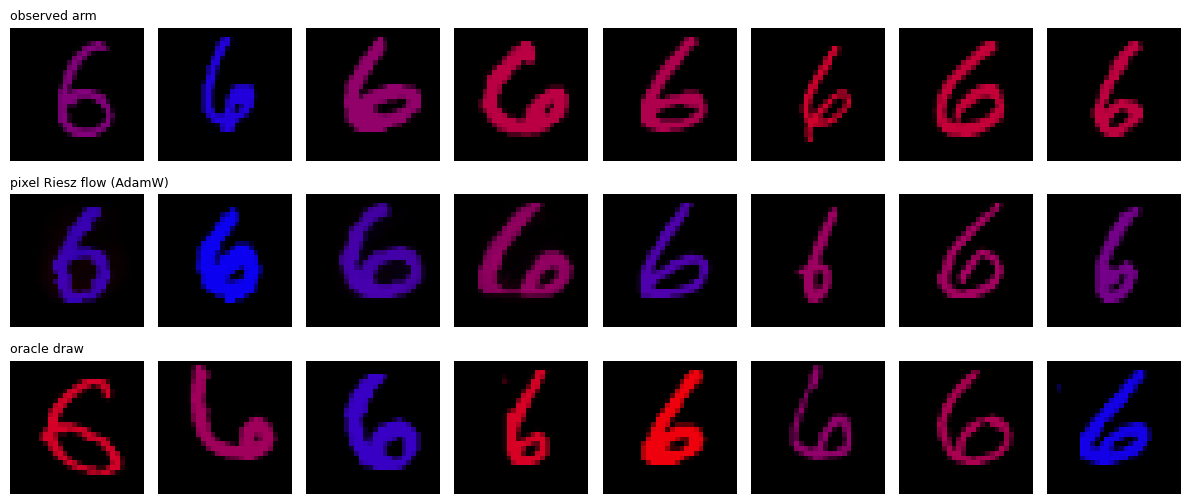

In [4]:
rows_to_show = [("observed arm", initial_images),
                ("pixel Riesz flow (AdamW)", flowed_images),
                ("oracle draw", Y_oracle)]
fig, axes = plt.subplots(len(rows_to_show), 8, figsize=(12, 1.75 * len(rows_to_show)))
for row, (label, images) in enumerate(rows_to_show):
    for column in range(8):
        axes[row, column].imshow(images[column].permute(1, 2, 0).cpu().clamp(0, 1).numpy())
        axes[row, column].axis("off")
    axes[row, 0].set_title(label, fontsize=9, loc="left")
fig.tight_layout()
plt.show()

## 4. The Colour Law

Kernel density of $\mathrm{logit}\, R/(R+B)$, the intervention's target statistic.

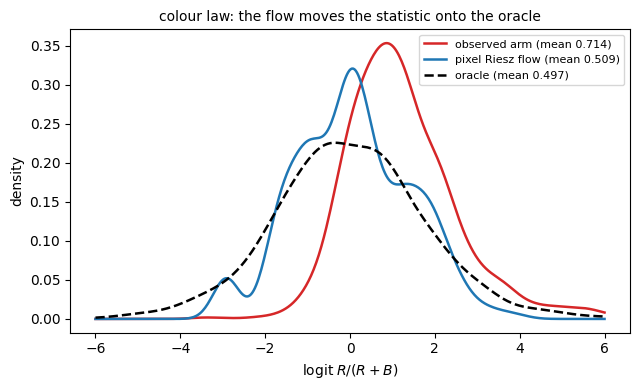

In [5]:
curves = {"observed arm": color_ratio(initial_images).cpu().numpy(),
          "pixel Riesz flow": color_ratio(flowed_images).cpu().numpy(),
          "oracle": color_ratio(Y_oracle).cpu().numpy()}
logit = lambda p: np.log(np.clip(p, 1e-4, 1 - 1e-4) / (1 - np.clip(p, 1e-4, 1 - 1e-4)))
grid = np.linspace(-6, 6, 400)

fig, ax = plt.subplots(figsize=(6.5, 4))
for (name, values), color, ls in zip(curves.items(), ("tab:red", "tab:blue", "k"),
                                     ("-", "-", "--")):
    ax.plot(grid, gaussian_kde(logit(values))(grid), lw=1.8, color=color, linestyle=ls,
            label=f"{name} (mean {values.mean():.3f})")
ax.set_xlabel(r"$\mathrm{logit}\; R/(R+B)$")
ax.set_ylabel("density")
ax.set_title("colour law: the flow moves the statistic onto the oracle", fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 5. Metrics

Against a fresh oracle draw. Reference values at this configuration: the latent IMQ
flow reaches colour $0.503$ / SW2 $0.0137$, the constrained encoder-pullback flow
$0.579$ / $0.0257$.

In [6]:
_, Y_oracle_2 = sample_interventional(pools, M, a=TARGET_A, tau=TAU, alpha=ALPHA,
                                      k_mask=K_MASK,
                                      generator=torch.Generator(device=device).manual_seed(SEED + 10))
kernel_eval = RBF(use_length_scale_heuristic=True)
_ = kernel_eval(flatten(Y_oracle))

print(f"{'sample':26s} {'colour mean(std)':>18s} {'SW1':>8s} {'SW2':>8s} {'MMD^2':>10s}")
for name, images in (("observed arm", initial_images),
                     ("pixel Riesz flow", flowed_images),
                     ("oracle-vs-oracle floor", Y_oracle_2)):
    ratio = color_ratio(images).cpu().numpy()
    sw1 = sliced_wasserstein(flatten(images), flatten(Y_oracle), p=1, seed=0).item()
    sw2 = sliced_wasserstein(flatten(images), flatten(Y_oracle), p=2, seed=0).item()
    mmd2 = squared_mmd(kernel_eval, flatten(images), flatten(Y_oracle), unbiased=True).item()
    print(f"{name:26s} {ratio.mean():>11.3f}({ratio.std():.3f}) {sw1:8.4f} {sw2:8.4f} {mmd2:10.2e}")

sample                       colour mean(std)      SW1      SW2      MMD^2
observed arm                     0.714(0.189)   0.0361   0.0474   3.84e-02
pixel Riesz flow                 0.509(0.258)   0.0227   0.0908   2.19e-03
oracle-vs-oracle floor           0.494(0.286)   0.0054   0.0079  -1.04e-04


## Summary

**The colour law is recovered.** The flow moves the observed arm's colour ratio from
$0.714$ to $0.509$ against an oracle $0.494$, and the density plot shows the whole
law — not just the mean — collapsing onto the oracle curve (spread $0.258$ vs
$0.286$). This is the closest colour recovery of any sampler apart from the latent
flow, achieved with no encoder, no decoder and no manifold anywhere in the sampler.

**The pixel distribution is not.** The flowed particles carry sparse runaway pixels
(raw range $[-15.9, 15.7]$ where valid images occupy $[-1, 1]$), and even after
clamping for display, SW2 *worsens* relative to doing nothing: $0.0474 \to 0.0908$
against a floor of $0.0079$. The latent flow reaches $0.0137$ on the same data and
weights.

**The three metrics disagree, exactly as their geometry predicts.** On the same
sample the colour statistic is essentially exact, unbiased RBF MMD$^2$ improves
seventeenfold ($3.8\mathrm{e}{-2} \to 2.2\mathrm{e}{-3}$), and SW2 nearly doubles —
the median-bandwidth kernel saturates on the outlying pixels while SW2 pays for them
linearly. The SW2 value is also the least stable across re-runs (0.079–0.091 for
otherwise identical runs), because it is dominated by a handful of particles. No
single one of these numbers would support a distributional claim.

**What this isolates.** With the encoder gone there is nothing to fool, so the
failure here is not the encoder-fooling of the pullback ablation: it is the absence
of a projection. Energy-distance transport moves the *statistic* correctly in raw
pixel space; the decoder is what turns correct moment transport into valid
*samples*.